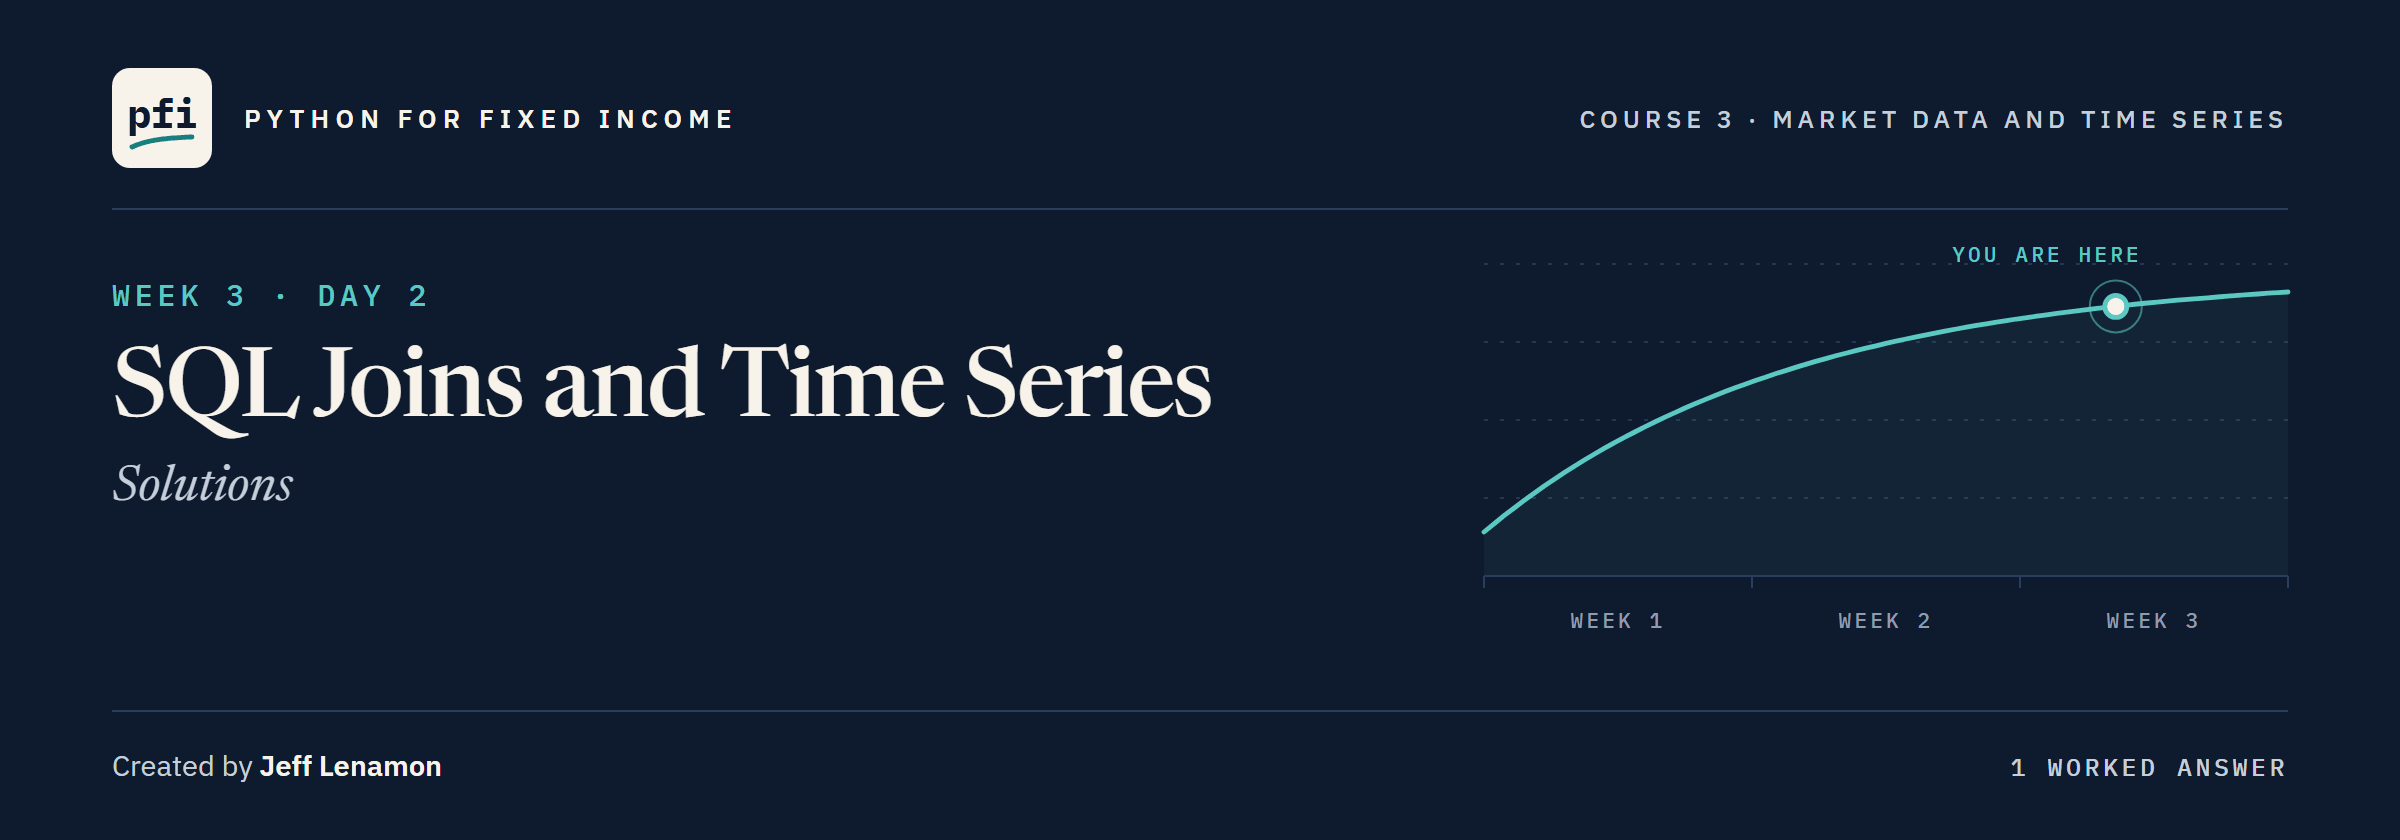

# SQL Joins and Time Series: Solutions

Week 3, Day 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day2/12_sql_joins_and_time_series_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the database, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 12 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(12, after=12)

Work folder pfi_course3_12_k4w7q2xr: 10 data files, Course 2's bondmath.py, marketdata.py as notebook 12 left it, 12 commits, tagged week1 and week2


In [2]:
import importlib

import pandas as pd

import marketdata as md
trades = pd.read_csv('trade_blotter.csv')
holdings = pd.read_csv('holdings.csv')
curve = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                    float_precision='round_trip')

In [3]:
# the treasury table in long form, as in the lesson, then three tables into course3.db
long = curve.reset_index().melt(id_vars='date', var_name='tenor', value_name='yield_pct').dropna()
long['date'] = long['date'].dt.strftime('%Y-%m-%d')
long.to_csv('treasury_long.csv', index=False)
db_path = work / 'course3.db'
md.load_tables(db_path, {'trades': 'trade_blotter.csv', 'holdings': 'holdings.csv',
                         'treasury': 'treasury_long.csv'})

{'trades': 374, 'holdings': 200, 'treasury': 35728}

In [4]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [5]:
ex1 = md.run_query(db_path, '''
    SELECT h.sector, t.side, SUM(t.principal) AS principal
    FROM trades AS t
    JOIN holdings AS h ON t.cusip = h.cusip
    GROUP BY h.sector, t.side''')
ex1_pandas = (trades.merge(holdings[['cusip', 'sector']], on='cusip', validate='many_to_one')
              .groupby(['sector', 'side'])['principal'].sum().reset_index())
md.assert_same_rows(ex1, ex1_pandas, sort_by=['sector', 'side'])

In [6]:
# the control figure: every trade's principal, once
assert round(ex1['principal'].sum(), 2) == round(trades['principal'].sum(), 2)
ex1_rows = len(ex1)
energy_buys = (ex1['sector'] == 'Energy') & (ex1['side'] == 'BUY')
ex1_energy_buy = ex1.loc[energy_buys, 'principal'].iloc[0]
check('Exercise 1 sector and side pairs', ex1_rows, 20)
check('Exercise 1 Energy buys', ex1_energy_buy, 9290328.45)

Exercise 1 sector and side pairs: correct
Exercise 1 Energy buys: correct


Ten sectors, each with buys and sells: 20 pairs, adding back to the blotter's 117,473,749.35 dollars.
Energy buys describe September's flow, not a view on the sector.

### Exercise 2

In [7]:
ex2 = md.run_query(db_path, '''
    SELECT date, yield_pct FROM (
        SELECT date, yield_pct,
            ROW_NUMBER() OVER (PARTITION BY substr(date, 1, 7) ORDER BY date DESC) AS row_in_month
        FROM treasury
        WHERE tenor = ? AND date BETWEEN ? AND ?
    ) WHERE row_in_month = 1
    ORDER BY date''', ('10 Yr', '2025-01-01', '2025-12-31'))
month_end = md.last_per_period(curve.loc['2025', '10 Yr'], 'ME')
ex2_pandas = pd.DataFrame({'date': month_end.index.strftime('%Y-%m-%d'),
                           'yield_pct': month_end.to_numpy()})
md.assert_same_rows(ex2, ex2_pandas, sort_by=['date'])

In [8]:
ex2_rows = len(ex2)
september = ex2[ex2['date'].str.startswith('2025-09')]
ex2_september_date = september['date'].iloc[0]
ex2_september_pct = september['yield_pct'].iloc[0]
check('Exercise 2 months', ex2_rows, 12)
check('Exercise 2 September date', ex2_september_date, '2025-09-30')
check('Exercise 2 September yield', ex2_september_pct, 4.16)

Exercise 2 months: correct
Exercise 2 September date: correct
Exercise 2 September yield: correct


Here the filter may sit inside: a whole year is whole months, so no month loses its last day.
The lesson's Excel `MAXIFS` and `XLOOKUP` check gave the same 12 rows.

### Exercise 3

In [9]:
%%writefile -a marketdata.py


def join_row_check(left: pd.DataFrame, right: pd.DataFrame, on: str) -> pd.DataFrame:
    """Left-join right onto left on one key column, and stop if the join changes left's row count.

    Units: unchanged. Convention: a lookup join keeps one row for each row of left; a key that repeats in
    right would add rows, so the row counts before and after are compared and must be equal.
    Raises ValueError naming both counts and the key if they differ.
    """
    joined = left.merge(right, on=on, how="left")
    if len(joined) != len(left):
        raise ValueError(f"joining on {on} turned {len(left)} rows into {len(joined)}")
    return joined

Appending to marketdata.py


In [10]:
%%writefile -a test_marketdata.py


def test_join_row_check_keeps_rows_and_stops_on_a_repeated_key():
    trades, holdings = pd.read_csv(HERE / "trade_blotter.csv"), pd.read_csv(HERE / "holdings.csv")
    # cusip is unique in holdings: one row per trade
    assert len(md.join_row_check(trades, holdings[["cusip", "sector"]], on="cusip")) == 374
    # ticker repeats in holdings: rows would be added, so the function stops
    with pytest.raises(ValueError):
        md.join_row_check(trades, holdings[["ticker", "sector"]], on="ticker")

Appending to test_marketdata.py


In [11]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.................................................                        [100%]
49 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_rows = len(md.join_row_check(trades, holdings[['cusip', 'sector']], on='cusip'))
try:
    md.join_row_check(trades, holdings[['ticker', 'sector']], on='ticker')
    ex3_stops = False
except ValueError as problem:
    ex3_stops = True
    print(problem)

joining on ticker turned 374 rows into 831


In [13]:
check('Exercise 3 rows kept on cusip', ex3_rows, 374)
check('Exercise 3 stops on ticker', ex3_stops, True)

Exercise 3 rows kept on cusip: correct
Exercise 3 stops on ticker: correct


The count before and after, turned into a check that stops: put it in front of any lookup join whose key you have not checked.

### Exercise 4: AI check

The bug: the join is on `ticker`, which names an issuer, so a trade in an issuer with three bonds in the book matches three rows.
831 rows and 252,709,336.05 dollars came back for 374 trades and 117,473,749.35, with no error.
"Ticker is in both tables" does not make a key; being unique on the lookup side does.
The fix joins on cusip.

In [14]:
# written for this course in the style of an AI assistant's answer, now fixed
def trades_with_sector(db_path):
    """Every trade of the blotter with the sector of the bond traded, one row per trade.

    Units: principal in dollars, as the blotter has it. Convention: exactly one row for each
    trade in the trades table, so the principal column sums to the blotter's total; the sector
    comes from holdings.
    """
    # the fix: cusip names one bond and is unique in holdings
    sql = '''
        SELECT t.trade_id, t.trade_date, t.side, t.principal, h.sector
        FROM trades AS t
        JOIN holdings AS h ON t.cusip = h.cusip'''
    return md.run_query(db_path, sql)

In [15]:
result = trades_with_sector(db_path)
print(f"{len(result)} rows, principal {result['principal'].sum():,.2f} dollars")
assert len(result) == len(trades), f'{len(result)} rows for {len(trades)} trades'
assert round(result['principal'].sum(), 2) == round(trades['principal'].sum(), 2)

374 rows, principal 117,473,749.35 dollars


In [16]:
ex4_rows = len(result)
ex4_principal = round(result['principal'].sum(), 2)
check('Exercise 4 one row per trade', ex4_rows, 374)
check("Exercise 4 the blotter's principal", ex4_principal, 117473749.35)

Exercise 4 one row per trade: correct
Exercise 4 the blotter's principal: correct


[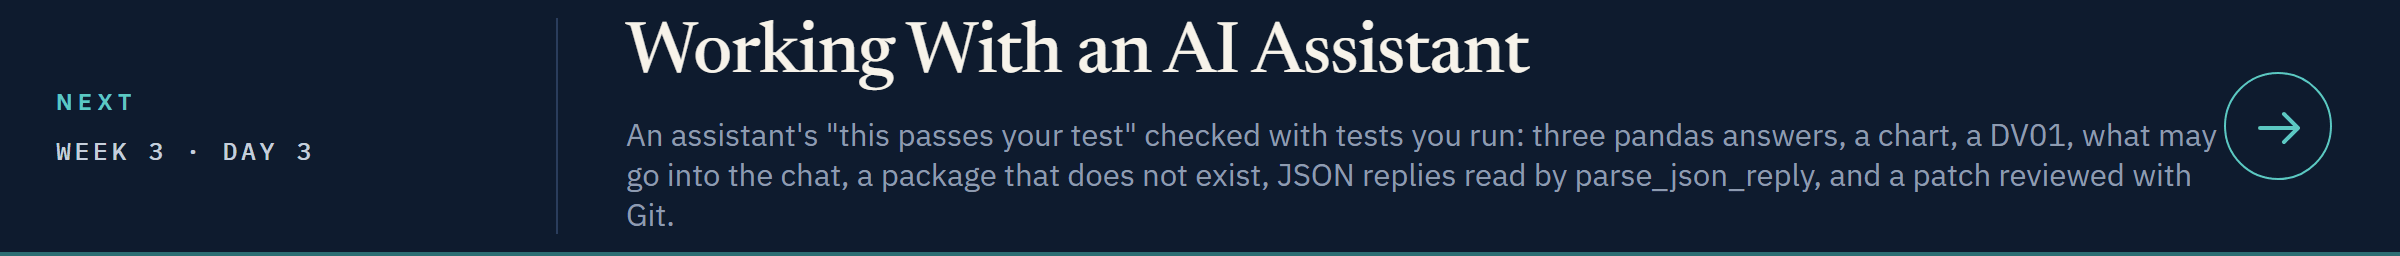](../day3/13_working_with_an_ai_assistant.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day3/13_working_with_an_ai_assistant.ipynb)